# Экономические соседи муниципалитетов
Ноутбук проверяет исходные данные, повторяет кластеризацию и строит графики
результатов. СберИндекс, направление «Кластеризация». Данные получены 09.10.2026.

## Основные результаты
Полная история охватывает 2 016 МО за 24 месяца. 1 003 МО не меняют согласованную
группу ни разу; средняя месячная доля переходов — 9,65%. Сеть потребительского
сходства выбрана для поиска аналогов, а не для рейтинга благосостояния.
KMeans имеет больший силуэт, чем выбранный сетевой метод.
Переходы и связь с доступностью рынков не доказывают причинность.

## Задача и методика
Вопрос: как меняются группы муниципалитетов, похожих по структуре потребления?
Методы реализованы в `src/prepare.py`, `src/network.py`, `src/pipeline.py`.
Ноутбук заново готовит панель и выполняет расчёт из исходных файлов.

### Допущения и ограничения
- Расходы — модельные средние безналичные расходы жителей, рубли.
- Доли нормируются на сумму пяти категорий, а не на все расходы.
- Пропуски не равны нулям. Используется полная панель фиксированных territory_id.
- Признаки sqrt(долей); веса kNN отражают сходство, а не потоки покупателей.
- Настройка только на январе 2023; затем параметры фиксированы.
- PCA служит отображением, не определяет соседей. Подробные метрики: `docs/metrics.md`.
- Два года не позволяют надёжно отделить сезонность от структурных изменений.

Источники: [официальный архив](https://www.sberbank.com/common/img/uploaded/files/pdf/sberindex/hackathonlicence.zip),
[справочник территорий](https://sberindex.ru/ru/research/dataset-borders-and-changes-of-municipalities).
Исходные и производные данные — СберИндекс, CC BY-SA 4.0. Изменения в проекте:
отбор полной панели, расчёт долей, сетей, групп и показателей.

### 1. Настройка среды и конфигурация
Перед открытием: `pip install -r requirements.txt`. Запуск из корня проекта либо `notebooks/`.

In [1]:
from pathlib import Path
import os, sys, json, contextlib, io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "config.json").is_file() and (p / "src/prepare.py").is_file())
os.chdir(ROOT)
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
os.environ["LOKY_MAX_CPU_COUNT"] = "2"
CONFIG = json.loads(Path("config.json").read_text())
plt.rcParams.update({"figure.figsize": (10, 4.6), "figure.dpi": 120,
    "font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": .2, "axes.axisbelow": True})
COLORS = ["#3568a5", "#728445", "#ca9643", "#c16688", "#986940"]
display(pd.Series(CONFIG, name="Конфигурация").to_frame())

Matplotlib is building the font cache; this may take a moment.


,Конфигурация
seed,42
neighbors,"[10, 15, 30]"
cluster_counts,"[3, 5, 8]"
louvain_resolutions,"[0.5, 1.0, 1.5]"
min_cluster_fraction,0.02
silhouette_sample_size,2000
stability_seeds,"[17, 31, 47]"


## Данные
### 2. Контроль файлов, схемы и полноты

In [2]:
from src.inventory import inventory
from src.prepare import prepare, CATEGORIES
files = inventory("data/raw")
display(pd.DataFrame(files["files"])[["file", "bytes", "sha256"]])
audit = prepare("data/raw/hackathonlicence", "data/processed")
display(pd.Series({k:v for k,v in audit.items() if not isinstance(v,list)}, name="Аудит").to_frame())
frame = pd.read_parquet("data/raw/hackathonlicence/consumption.parquet")
assert not frame.duplicated(["territory_id", "date", "category"]).any()
assert not frame.isna().any().any()
assert (frame.value > 0).all()
panel = np.load("data/processed/panel.npz")
assert np.allclose(panel["shares"].sum(axis=2), 1)
assert np.all(panel["values"].sum(axis=2) <= panel["total"])
assert audit["included_ids"] == 2016 and audit["excluded_ids"] == 174
display(Markdown("**Проверки пройдены:** ключи уникальны, значения положительны; доли суммируются в 1, корзина не превышает total."))

,file,bytes,sha256
0,hackathonlicence/connection.parquet,21904682,20cbd5213d3ac1d0a867f097b485431811614b283d7366...
1,hackathonlicence/consumption.parquet,2373939,9833ddaaee7b2a182ed4cceeed16469031700ea87d508b...
2,hackathonlicence/market_access.parquet,25163,434258afe322b7e6e6610b2552d129ae47094613de72da...
3,hackathonlicence/Данные_СберИндекс_лицензия.pdf,538791,030269e726f969250b911a1fcb72131a4b61c3952aad10...
4,hackathonlicence.zip,19603203,a9f932ff4096a7df797d1547987937f34d3995ac445b47...
5,t_dict_municipal.rar,26925727,319ed22684b77716641bc15b61f7325adc44e9fc47e9be...
6,t_dict_municipal_districts.xlsx,322024,4150658c3298fbc87ed79838f503f3a5b9a28da33257ff...


,Аудит
source_ids,2190
included_ids,2016
excluded_ids,174
source_rows,303126
missing_panel_rows,12234
measure,"Оценка средних безналичных расходов жителей, р..."
denominator,"Сумма пяти выбранных категорий, не все расходы"
source_sha256,9833ddaaee7b2a182ed4cceeed16469031700ea87d508b...


**Проверки пройдены:** ключи уникальны, значения положительны; доли суммируются в 1, корзина не превышает total.

### 3. Где отсутствуют наблюдения
Знаменатель: 2 190 исходных МО × 6 категорий в каждом месяце. Это пропущенные строки, не нулевые расходы.

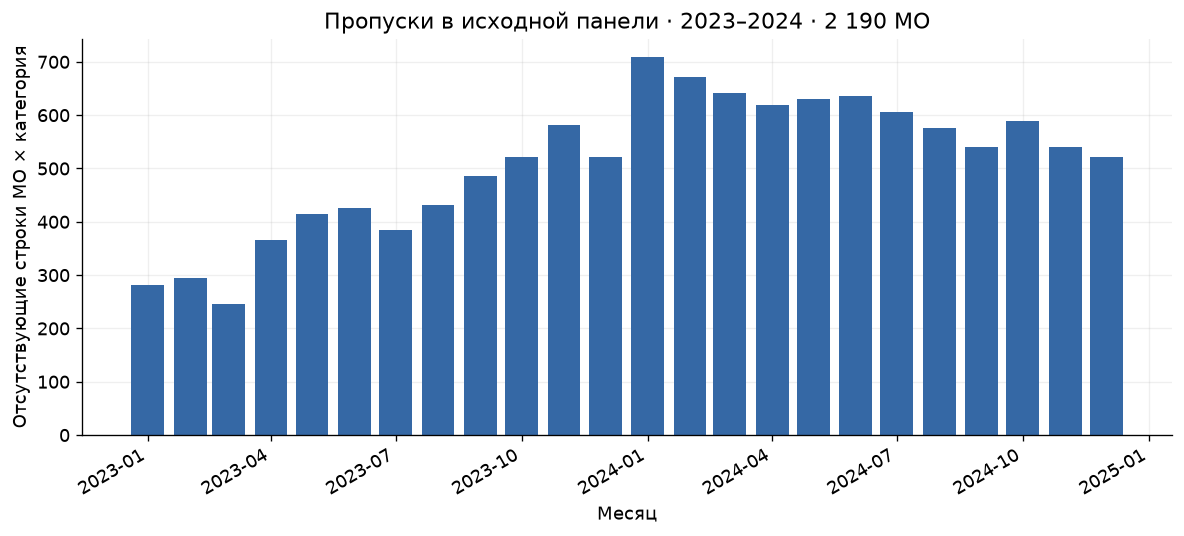

Отсутствуют **12,234** строк (**3.88%**). Для динамики оставлены МО с полной историей; это может влиять на представительность.

In [3]:
expected = frame.territory_id.nunique() * frame.category.nunique()
missing = (expected - frame.groupby("date").size()).reindex(panel["months"])
assert missing.sum() == audit["missing_panel_rows"]
fig, ax = plt.subplots()
ax.bar(pd.to_datetime(missing.index), missing.values, width=24, color=COLORS[0])
ax.set(title="Пропуски в исходной панели · 2023–2024 · 2 190 МО", ylabel="Отсутствующие строки МО × категория", xlabel="Месяц")
fig.autofmt_xdate(); fig.tight_layout(); plt.show()
display(Markdown(f"Отсутствуют **{missing.sum():,}** строк (**{missing.sum() / (expected*24):.2%}**). Для динамики оставлены МО с полной историей; это может влиять на представительность."))

### 4. Проверка вспомогательных таблиц
Дороги и железные дороги — статический срез конца 2024, не измерение мобильности. В модели используется только автомобильная близость, и только в дополнительном сравнении.

In [4]:
connections = pd.read_parquet("data/raw/hackathonlicence/connection.parquet")
connection_audit = []
for kind, part in connections.groupby("type"):
    pairs = pd.DataFrame({"a":np.minimum(part.territory_id_x, part.territory_id_y),
                          "b":np.maximum(part.territory_id_x, part.territory_id_y)})
    connection_audit.append({"Тип":kind, "Строк":len(part),
        "Неположительных расстояний":int((part.distance<=0).sum()),
        "Повторов неупорядоченных пар":int(pairs.duplicated().sum())})
display(pd.DataFrame(connection_audit))
market = pd.read_parquet("data/raw/hackathonlicence/market_access.parquet")
assert not market.territory_id.duplicated().any()
display(pd.DataFrame({"Источник":["Доступность рынков"], "МО":[len(market)],
    "Минимум":[market.market_access.min()], "Максимум":[market.market_access.max()]}))
del connections
display(Markdown("148 неположительных дорожных расстояний исключаются. Дубли обратных железнодорожных пар не интерпретируются как дополнительные связи; железные дороги в модель не входят."))

,Тип,Строк,Неположительных расстояний,Повторов неупорядоченных пар
0,highway,3303736,148,0
1,railway,2638628,0,1319314


,Источник,МО,Минимум,Максимум
0,Доступность рынков,2571,110.3,1000.0


148 неположительных дорожных расстояний исключаются. Дубли обратных железнодорожных пар не интерпретируются как дополнительные связи; железные дороги в модель не входят.

## Результаты расчёта
### 5. Повторный расчёт
Ход расчёта записывается в `outputs/analysis/notebook-run.log`. Результаты сохраняются в `outputs/analysis/`.

In [5]:
from src.pipeline import run
from threadpoolctl import threadpool_limits
with open("outputs/analysis/notebook-run.log", "w") as log, contextlib.redirect_stdout(log), threadpool_limits(limits=2):
    summary = run("data/processed", "data/raw/hackathonlicence", "config.json", "outputs/analysis")
base = Path("outputs/analysis")
comparison = pd.read_csv(base/"comparison.csv")
dynamics = pd.read_csv(base/"dynamics.csv")
smoothing = pd.read_csv(base/"smoothing-sensitivity.csv")
profiles = pd.read_csv(base/"profiles.csv")
display(pd.Series(summary["selected"], name="Выбрано на январе 2023").to_frame())

,Выбрано на январе 2023
month,2023-01
graph,hellinger
method,spectral
neighbors,30
parameter,3
clusters,3
min_cluster_fraction,0.122024
SW,0.250817
CH,948.73971
DB,1.220236


### 6. Сравнение методов на одной сети
Показаны лучшие по SW конфигурации каждого метода при kNN=30 и минимальном размере группы 2%. Полные 27 вариантов — `comparison.csv`. Сетевой метод выбирается среди Spectral и Louvain; KMeans — признаковый ориентир.

,method,parameter,clusters,SW,CH,S_Dbw,AVI,AVU,MQ
18,kmeans,3.0,3,0.3208,1313.1058,1.1804,0.9250,0.6667,0.5770
21,spectral,3.0,3,0.2508,948.7397,0.8884,0.9371,0.6667,0.5305
24,louvain,0.5,5,0.2285,904.6757,0.6870,0.8767,0.5640,0.6689


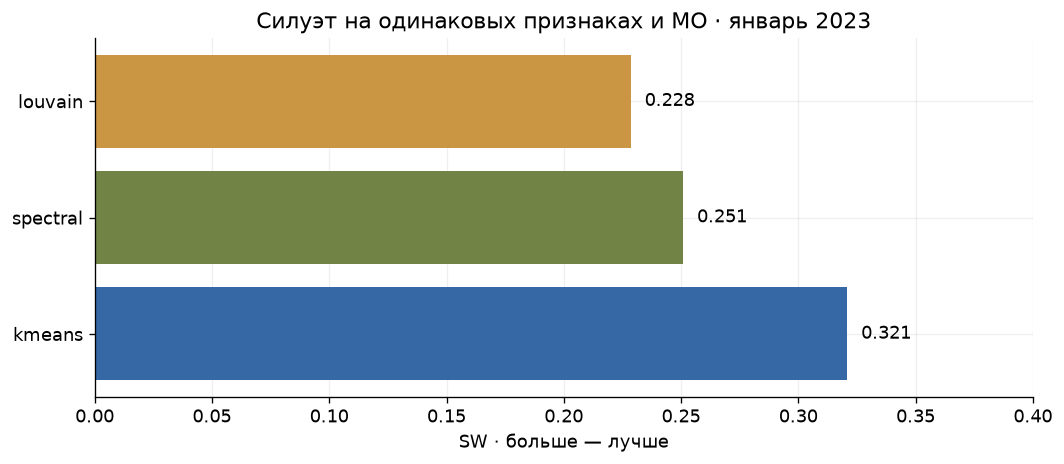

KMeans разделяет признаки лучше по SW; Spectral выбран для исследования сети. Высокие сетевые индексы на графе из тех же признаков не являются внешней валидацией.

In [6]:
same_graph = comparison[(comparison.neighbors==30) & (comparison.min_cluster_fraction>=.02)]
best = same_graph.sort_values("SW",ascending=False).groupby("method",sort=False).head(1)
display(best[["method", "parameter", "clusters", "SW", "CH", "S_Dbw", "AVI", "AVU", "MQ"]].round(4))
fig, ax = plt.subplots(figsize=(9,4))
ax.barh(best.method, best.SW, color=COLORS[:len(best)])
ax.set(xlim=(0,.4), xlabel="SW · больше — лучше", title="Силуэт на одинаковых признаках и МО · январь 2023")
for y,value in enumerate(best.SW): ax.text(value+.006,y,f"{value:.3f}",va="center")
fig.tight_layout(); plt.show()
display(Markdown("KMeans разделяет признаки лучше по SW; Spectral выбран для исследования сети. Высокие сетевые индексы на графе из тех же признаков не являются внешней валидацией."))

### 7. Как менялась корзина
Каждый МО имеет одинаковый вес. Доля — от суммы пяти категорий. Это не распределение всех расходов населения России.

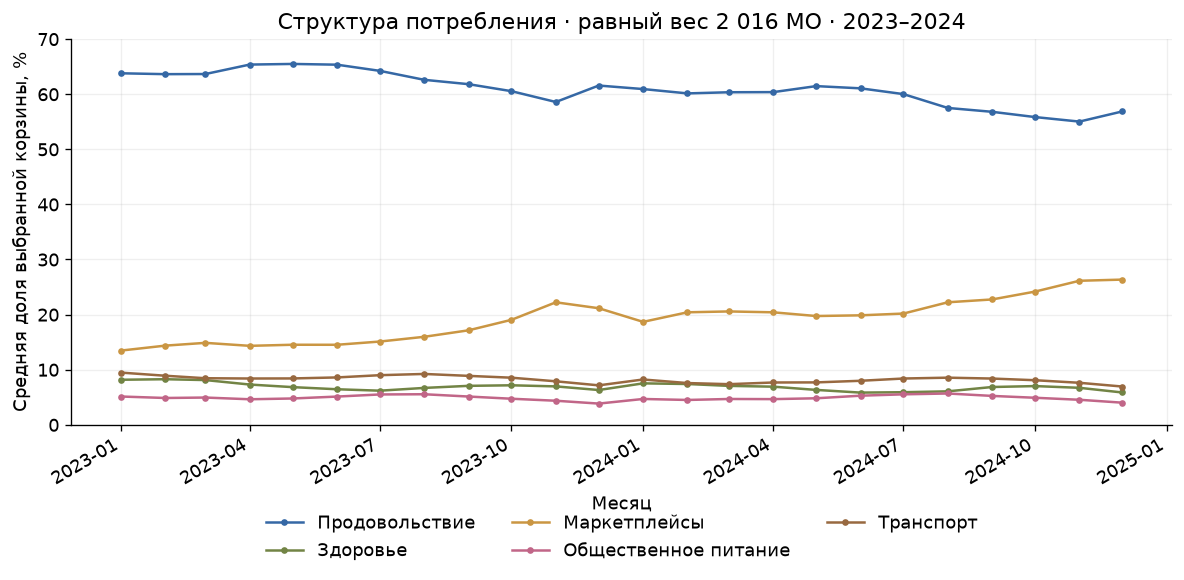

,Категория,"Январь 2023, %","Декабрь 2024, %"
0,Продовольствие,63.78,56.86
1,Здоровье,8.17,5.86
2,Маркетплейсы,13.46,26.34
3,Общественное питание,5.13,4.01
4,Транспорт,9.46,6.93


Маркетплейсы занимают большую долю выбранной корзины к концу периода. Сравнение января с декабрём не очищено от сезонности; изменение долей не равно изменению доходов.

In [7]:
basket = panel["shares"].mean(axis=1)
fig, ax = plt.subplots(figsize=(10,5))
for index, category in enumerate(CATEGORIES):
    ax.plot(pd.to_datetime(panel["months"]), 100*basket[:,index],
            color=COLORS[index], label=category, marker="o", markersize=3)
ax.set(ylabel="Средняя доля выбранной корзины, %", xlabel="Месяц", ylim=(0,70),
       title="Структура потребления · равный вес 2 016 МО · 2023–2024")
ax.legend(loc="upper center",bbox_to_anchor=(.5,-.19),ncol=3,frameon=False)
fig.autofmt_xdate(); fig.tight_layout(); plt.show()
display(pd.DataFrame({"Категория":CATEGORIES,"Январь 2023, %":100*basket[0],
                      "Декабрь 2024, %":100*basket[-1]}).round(2))
display(Markdown("Маркетплейсы занимают большую долю выбранной корзины к концу периода. Сравнение января с декабрём не очищено от сезонности; изменение долей не равно изменению доходов."))

### 8. Переходы и сглаживание на одинаковых месяцах
Для обоих рядов 21 переход: апрель 2023 — декабрь 2024. Сглаживание: среднее уровней за три текущих/предыдущих месяца, затем новые доли и группы.

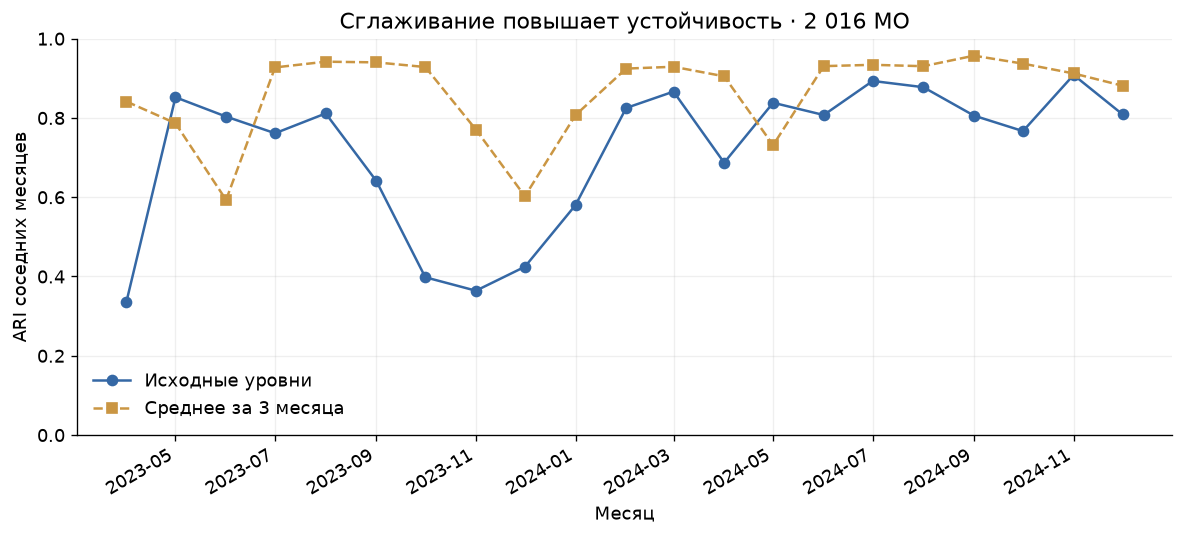

,Показатель,Значение
0,"Средний ARI исходного ряда, общие месяцы",0.7169
1,"Средний ARI сглаженного ряда, общие месяцы",0.8623
2,Минимальный ARI проверки seeds,0.9899
3,Средний ARI одинаковых месяцев 2023/2024,0.5428


**1,003** МО сохранили группу во всех месяцах. Средняя доля переходов во всём периоде: **9.65%**. Сглаживание уменьшает краткосрочную вариативность, но не устраняет сезонность.

In [8]:
common = smoothing.dropna(subset=["ARI_previous_trailing3", "ARI_previous_raw"])
assert len(common)==21
fig, ax = plt.subplots()
ax.plot(pd.to_datetime(common.month),common.ARI_previous_raw,label="Исходные уровни",color=COLORS[0],marker="o")
ax.plot(pd.to_datetime(common.month),common.ARI_previous_trailing3,label="Среднее за 3 месяца",color=COLORS[2],linestyle="--",marker="s")
ax.set(ylim=(0,1), ylabel="ARI соседних месяцев", xlabel="Месяц",title="Сглаживание повышает устойчивость · 2 016 МО")
ax.legend(frameon=False); fig.autofmt_xdate(); fig.tight_layout(); plt.show()
seed_check = pd.read_csv(base/"seed-stability.csv")
yearly = pd.read_csv(base/"same-month-year.csv")
display(pd.DataFrame({"Показатель":["Средний ARI исходного ряда, общие месяцы", "Средний ARI сглаженного ряда, общие месяцы", "Минимальный ARI проверки seeds", "Средний ARI одинаковых месяцев 2023/2024"],
    "Значение":[common.ARI_previous_raw.mean(),common.ARI_previous_trailing3.mean(),seed_check.ARI_to_seed42.min(),yearly.ARI.mean()]}).round(4))
display(Markdown(f"**{summary['never_changed']:,}** МО сохранили группу во всех месяцах. Средняя доля переходов во всём периоде: **{summary['mean_changed_fraction']:.2%}**. Сглаживание уменьшает краткосрочную вариативность, но не устраняет сезонность."))

### 9. Потребительская и транспортная близость
Три подхода рассчитаны на одинаковых 2 004 МО крупнейшей дорожной компоненты, декабрь 2024; Spectral, K=3, kNN=30. Оценка в одном потребительском пространстве.

In [9]:
proximity = pd.read_csv(base/"proximity-common-population.csv")
display(proximity[["graph", "municipalities", "clusters", "SW", "CH", "S_Dbw", "AVI", "AVU", "MQ"]].round(4))
assert proximity.municipalities.nunique()==1
display(Markdown("Дорожные группы почти не разделяют потребительские профили (SW около 0,004). Это аргумент для поиска аналогов по расходам, а не оценка транспортной эффективности."))

,graph,municipalities,clusters,SW,CH,S_Dbw,AVI,AVU,MQ
0,hellinger,2004,3,0.3204,1222.7112,0.7044,0.9398,0.6667,0.4905
1,cosine,2004,3,0.2188,918.8279,1.1233,0.9547,0.6667,0.5623
2,road,2004,3,0.0036,203.2302,1.5442,0.9967,0.6667,0.4221


Дорожные группы почти не разделяют потребительские профили (SW около 0,004). Это аргумент для поиска аналогов по расходам, а не оценка транспортной эффективности.

### 10. Внешний показатель: доступность рынков
Показатель 2024 года не включён в обучение. Выборка — 2 004 МО с известной доступностью; это отдельное правило отбора от дорожного сравнения.

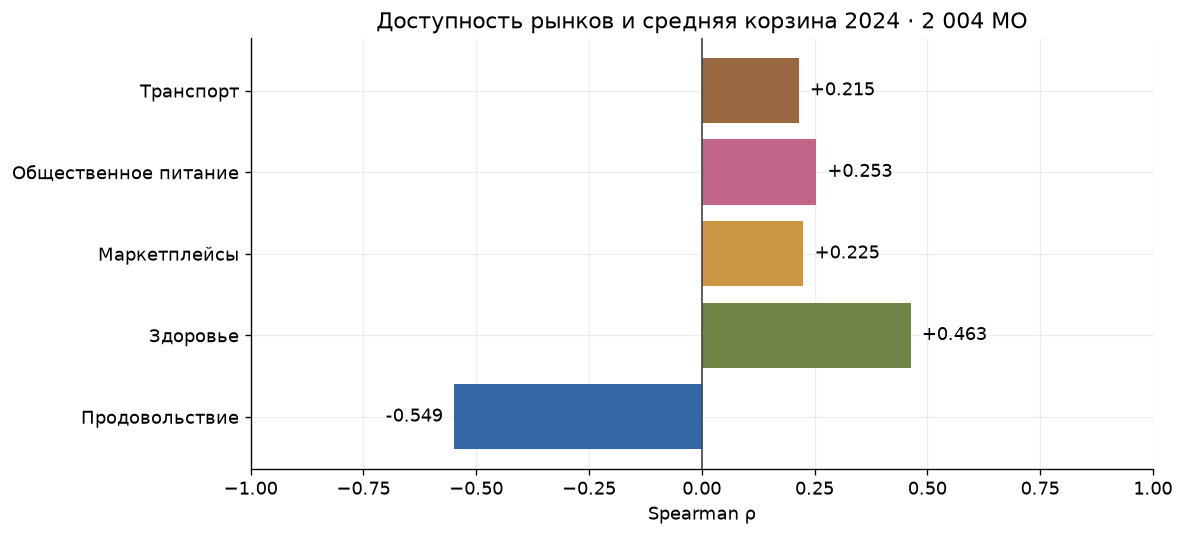

,category,n,rho
0,Продовольствие,2004,-0.5492
1,Здоровье,2004,0.4628
2,Маркетплейсы,2004,0.2252
3,Общественное питание,2004,0.2533
4,Транспорт,2004,0.2146


Продовольственная доля отрицательно связана с доступностью, доля здоровья — положительно. Возможны общие причины и композиционные зависимости; причинный эффект не установлен.

In [10]:
associations = pd.read_csv(base/"market-associations.csv")
fig, ax = plt.subplots(figsize=(10,4.6))
ax.barh(associations.category, associations.rho, color=COLORS)
ax.axvline(0,color="#444444",linewidth=1)
ax.set(xlim=(-1,1), xlabel="Spearman ρ",title="Доступность рынков и средняя корзина 2024 · 2 004 МО")
for index,value in enumerate(associations.rho):
    ax.text(value+(.025 if value>=0 else -.025),index,f"{value:+.3f}",
            ha="left" if value>=0 else "right",va="center")
fig.tight_layout(); plt.show()
display(associations[["category", "n", "rho"]].round(4))
display(Markdown("Продовольственная доля отрицательно связана с доступностью, доля здоровья — положительно. Возможны общие причины и композиционные зависимости; причинный эффект не установлен."))

## Выводы
Практическая цель — выбрать потребительские аналоги муниципалитета и проверить,
как их профиль и состав меняются по месяцам. Фиксированная PCA-проекция используется
для отображения профилей; соседи определяются по полному пространству признаков.
Пример паспорта Майкопа приведён в презентации. Истории и связи всех МО сохранены
в `outputs/analysis/explorer-nodes.json`.

Группы описательны. Их нельзя прямо считать рейтингом благосостояния, инвестиционной
привлекательности или работы администрации. Не идентифицированы влияния покрытия
банка, наличных, инфляции и состава жителей.

Исполняемый код и исходные определения доступны в проекте; контрольные суммы —
`outputs/input-inventory.json`, метрики — `docs/metrics.md`, методологический отчёт —
`docs/methodological-report.md`. Лицензия данных: **CC BY-SA 4.0**, СберИндекс.